In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load

df = pd.read_csv("data/weather.csv", parse_dates = ["time"], usecols = ["time", "cloud_cover", "shortwave_radiation"])
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2025-06-01", "2025-07-01", inclusive="left")]

df.head()

/var/folders/ws/zvmm_zdd17bdq7jp8n47wwxw0000gn/T/ipykernel_21670/250889418.py:3: DtypeWarning: Columns (8: cloud_cover) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/weather.csv", parse_dates = ["time"], usecols = ["time", "cloud_cover", "shortwave_radiation"])


,time,cloud_cover,shortwave_radiation
222791,2025-06-01 00:00:00-06:00,46,0.0
222792,2025-06-01 01:00:00-06:00,43,0.0
222793,2025-06-01 02:00:00-06:00,34,0.0
222794,2025-06-01 03:00:00-06:00,64,0.0
222795,2025-06-01 04:00:00-06:00,99,0.0


In [3]:
# Inspect dtype issue
# Expected int type for cloud cover

non_numeric = df.loc[~df["cloud_cover"].astype("string").str.fullmatch(r"\d+(\.\d+)?", na = False), ["time", "cloud_cover"]]

display(non_numeric)

,time,cloud_cover
222875,2025-06-04 12:00:00-06:00,43%
223030,2025-06-10 23:00:00-06:00,23%
223174,2025-06-16 23:00:00-06:00,97%
223175,2025-06-17 00:00:00-06:00,86%
223176,2025-06-17 01:00:00-06:00,92%
223263,2025-06-20 16:00:00-06:00,100%
223272,2025-06-21 01:00:00-06:00,100%
223273,2025-06-21 02:00:00-06:00,100%
223274,2025-06-21 03:00:00-06:00,100%
223464,2025-06-29 01:00:00-06:00,0%


In [4]:
# Clean
# Seems like some cloud_cover values mistakenly include the %.

df_clean = df.copy()

df_clean["cloud_cover"] = pd.to_numeric(df["cloud_cover"].astype("string").str.strip().str.removesuffix("%").str.strip(), errors = "coerce")

non_numeric = df_clean.loc[~df_clean["cloud_cover"].astype("string").str.fullmatch(r"\d+(\.\d+)?", na = False), ["time", "cloud_cover"]]

display(non_numeric)

,time,cloud_cover


In [5]:
# Full Inspect

# Structure
print(df_clean["time"].min(), "to", df_clean["time"].max(), "\n")
print("Shape:", df_clean.shape, "\n")
print("Dtypes:")
print(df_clean.dtypes, "\n")

# Missingness
print("Any Nulls:", df_clean.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df_clean.duplicated().any())
print("Duplicate Times:", df_clean["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df_clean["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df_clean["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df_clean[["cloud_cover", "shortwave_radiation"]].describe().T)

2025-06-01 00:00:00-06:00 to 2025-06-30 23:00:00-06:00 

Shape: (720, 3) 

Dtypes:
time                   datetime64[us, America/Edmonton]
cloud_cover                                       Int64
shortwave_radiation                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False 



,count,mean,std,min,25%,50%,75%,max
cloud_cover,720.0,51.231944,37.669381,0.0,12.0,52.0,92.0,100.0
shortwave_radiation,720.0,289.459722,310.724092,0.0,0.0,146.0,570.0,929.0


In [6]:
# Transform

filter_df = df_clean.loc[df_clean["time"].dt.hour.between(8, 20, inclusive = "left")].copy()

filter_df["bins"] = pd.cut(filter_df["cloud_cover"],  
                           bins = [0, 25, 50, 75, 100], 
                           labels = ["0–25%", "25–50%", "50–75%", "75–100%"], 
                           include_lowest = True)

# Validate

print("Unassigned Bins:", filter_df["bins"].isna().sum())
print("Unexpected Daytime Observations:", 30 * 12 - len(filter_df), "\n")

output_df = (filter_df.groupby("bins", as_index = False, observed = False)
                      .agg(avg_radiation = ("shortwave_radiation", "mean"),
                           count = ("bins", "size")))

display(output_df)

Unassigned Bins: 0
Unexpected Daytime Observations: 0 



,bins,avg_radiation,count
0,0–25%,587.440860,93
1,25–50%,628.742424,66
2,50–75%,618.173333,75
3,75–100%,427.730159,126


In [7]:
# 0-25% bin is lower than I'd expect
# I want to see if that can be explained by average hour

hour_df = filter_df.copy()

hour_df["hour"] = (filter_df["time"].dt.hour + filter_df["time"].dt.minute.div(60))

output_df = (hour_df.groupby("bins", as_index = False, observed = False)
                    .agg(avg_radiation = ("shortwave_radiation", "mean"),
                         count = ("bins", "size"),
                         avg_hour = ("hour", "mean")))

display(output_df)

,bins,avg_radiation,count,avg_hour
0,0–25%,587.440860,93,11.698925
1,25–50%,628.742424,66,13.363636
2,50–75%,618.173333,75,14.826667
3,75–100%,427.730159,126,14.111111


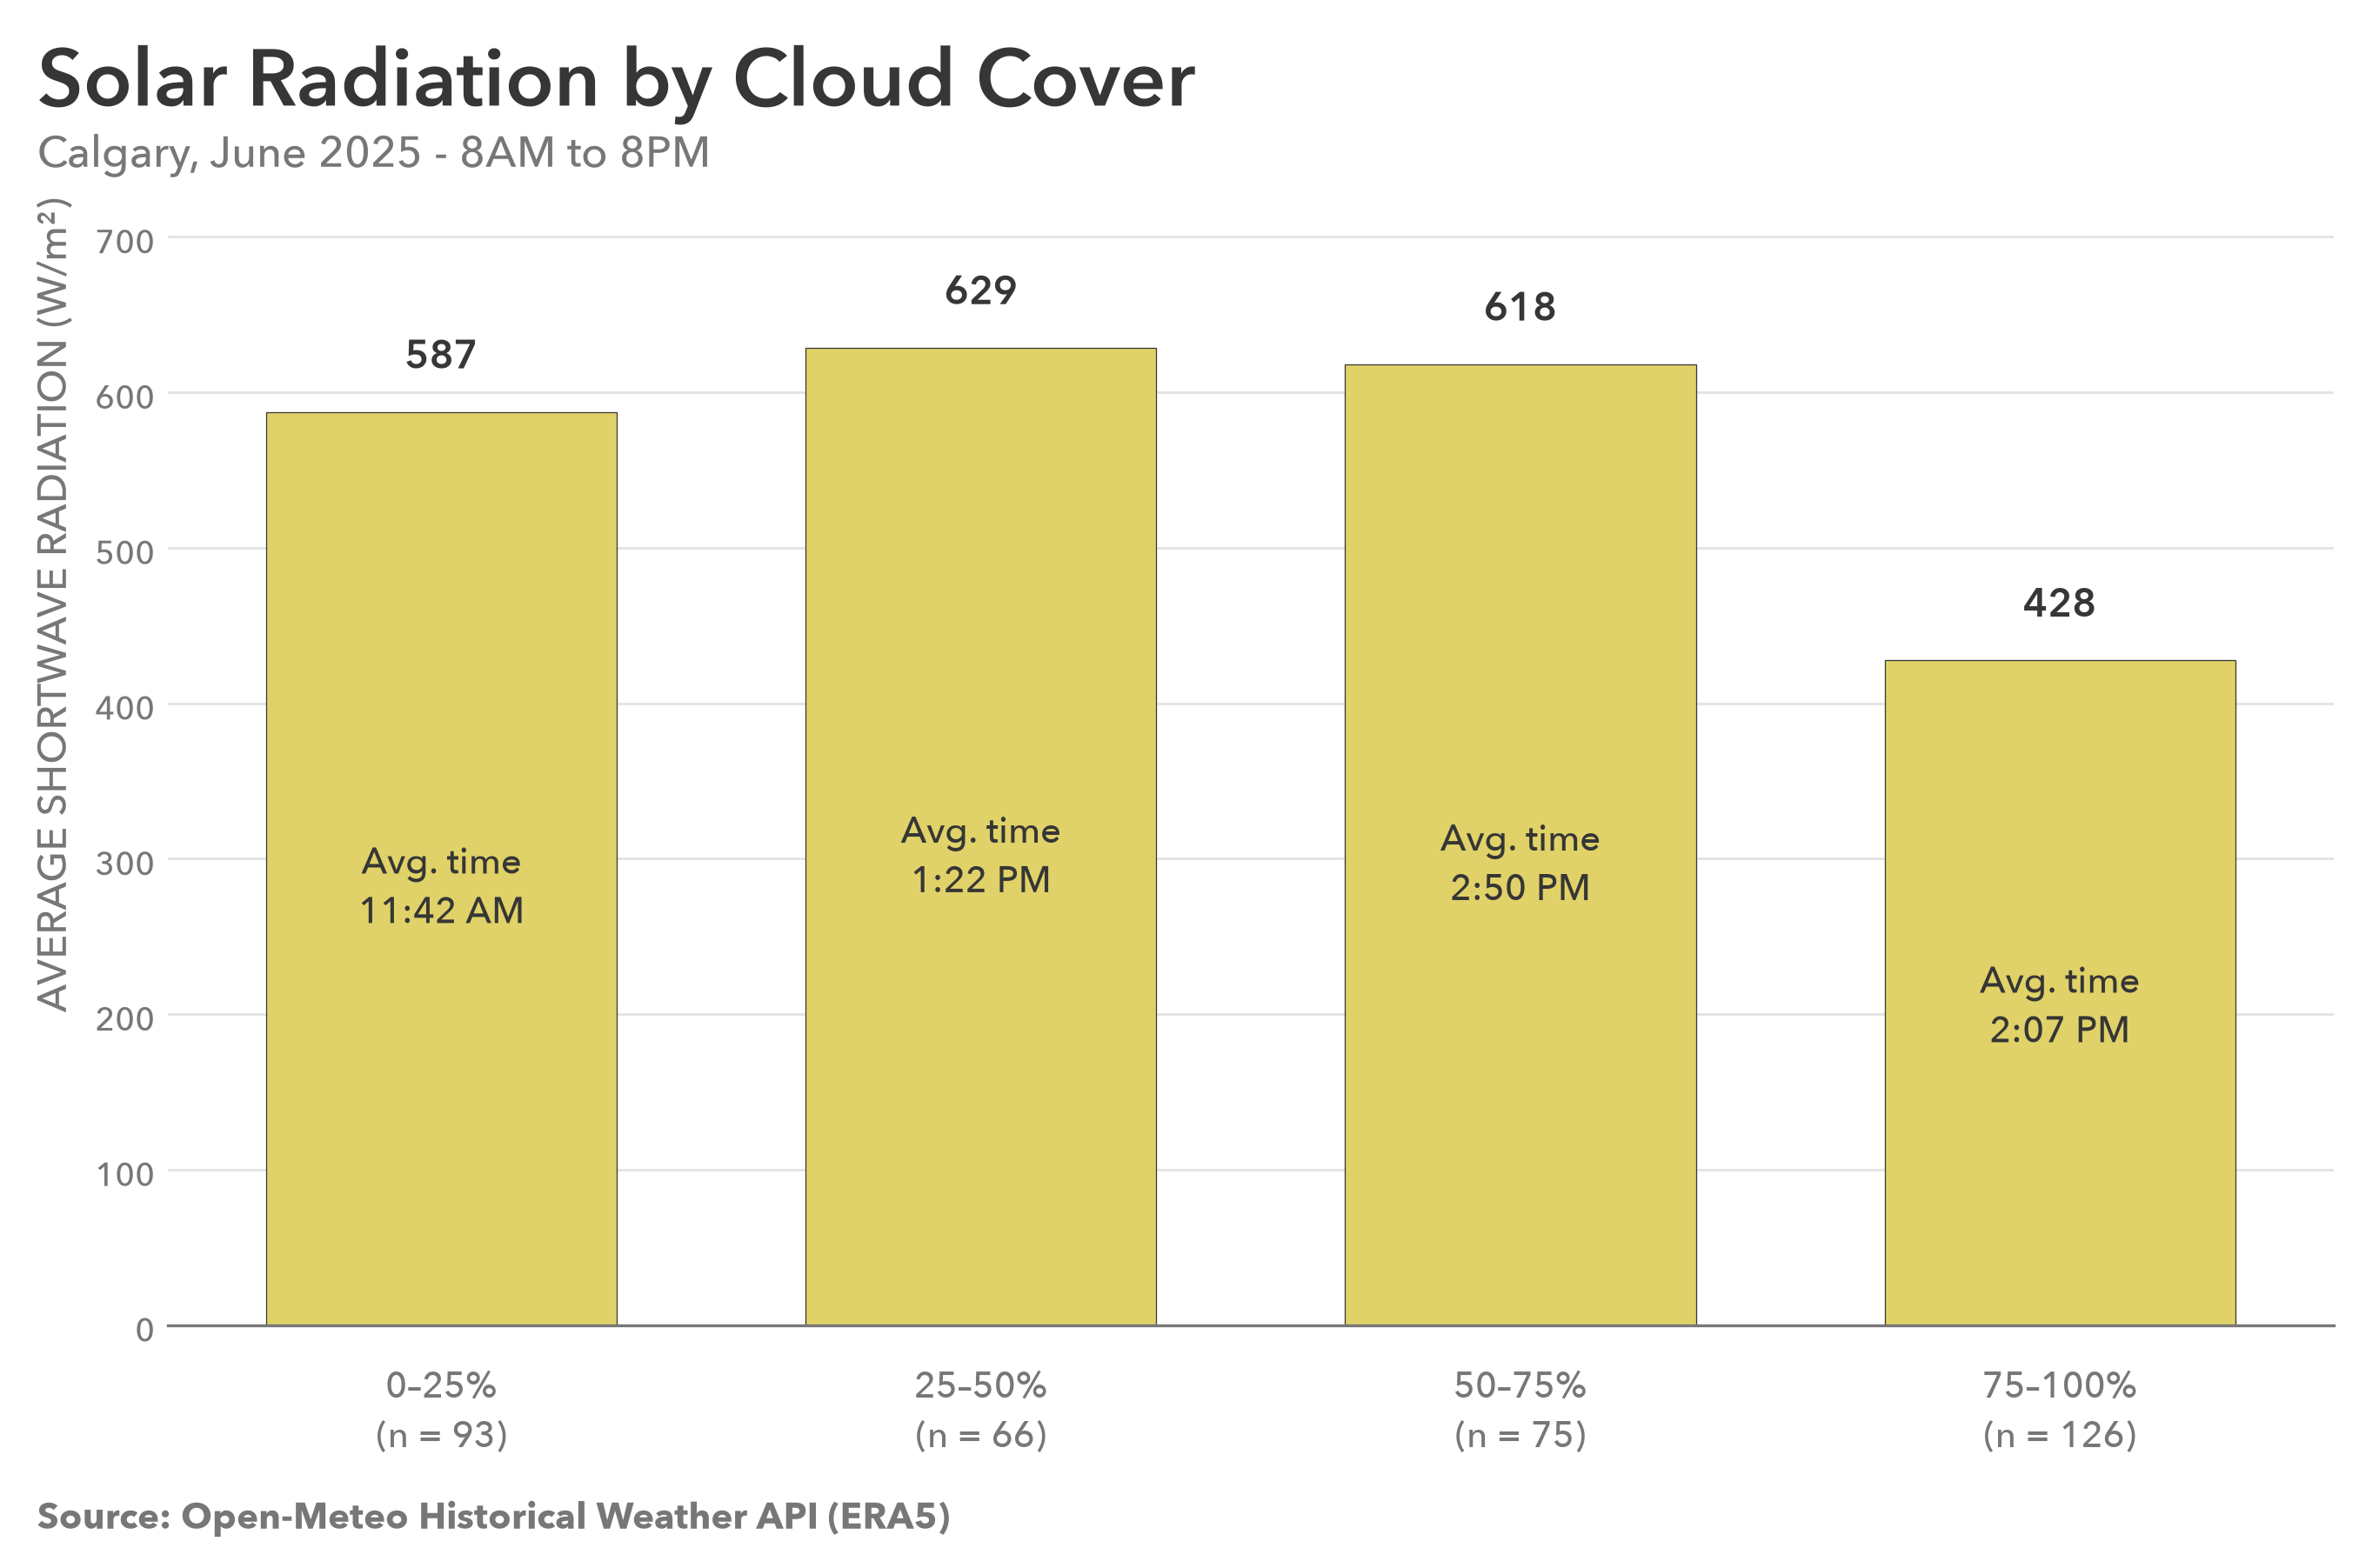

In [8]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (10, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.93,
    top = 0.85,
    bottom = 0.13
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
YELLOW = "#E0D268"
TITLE = "#363636"

# Plot

x = range(len(output_df))

bars = ax.bar(x, output_df["avg_radiation"], width = 0.65, color = YELLOW, edgecolor = TITLE, linewidth = 0.3)

# Emphasis

# average radiation above bars
for bar, radiation in zip(bars, output_df["avg_radiation"]):
    ax.annotate(f"{radiation:.0f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext = (0, 8), textcoords = "offset points",
                ha = "center", va = "bottom",
                fontsize = 11, fontweight = 600, color = TITLE)

# average observation time inside bars
for bar, avg_hour in zip(bars, output_df["avg_hour"]):
    hour, minute = divmod(round(avg_hour * 60), 60)
    time_label = f"{(hour - 1) % 12 + 1}:{minute:02d} {'AM' if hour < 12 else 'PM'}"

    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() * 0.48,
            f"Avg. time\n{time_label}",
            ha = "center", va = "center",
            fontsize = 10, fontweight = 500, color = TITLE)

# Scale & Axes

ax.set_ylim(0, 725)

ax.set_ylabel("AVERAGE SHORTWAVE RADIATION (W/m²)", loc = "top", fontsize = 11, fontweight = 500, color = STRUCTURE)

# Ticks

labels = [f"{band}\n(n = {count})" for band, count in zip(output_df["bins"], output_df["count"])]

ax.set_xticks(list(x), labels)

ax.tick_params(axis = "x", labelsize = 10, length = 0, pad = 10, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(axis = "y", color = GRID, linewidth = 0.7, alpha = 0.35)

# Composition

fig.suptitle("Solar Radiation by Cloud Cover", x = 0.05, y = 0.96, ha = "left", va = "top", fontweight = 600, fontsize = 22, color = TITLE)

fig.text(0.05, 0.87, "Calgary, June 2025 - 8AM to 8PM", fontsize = 12, color = STRUCTURE)

fig.text(0.05, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 10, fontweight = 700, color = STRUCTURE)

# Output

fig.savefig("outputs/solar-radiation-by-cloud-cover-june-2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()